In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams # detailed parameter setting
""" more details on customization: https://matplotlib.org/stable/tutorials/introductory/customizing.html """
from typing import Dict, List, Union

# HW 2/1

Smart up our plotter to be able to customize the hard-coded layout setup inside the function. Add more custom feature that you would like to use.

Updated
* linestyle
* linewidth
* x_label_font
* y_label_font


In [2]:
# some type hints in the header of the function
def my_plotter(x: List[float], y: Union[List[float], List[List[float]]], layout: Dict = {}, names: List[str] = None) -> None:
    """ inline for loop is called 'list comprehension' """
    y = [y] if all(isinstance(item, float) for item in y) else y
    
    plt.figure(figsize=(8, 4))
    lines = []
    show_legend = True if names is not None else False
    # show_legend = True if names else False  -> here is fine, but be cautious bc 0, empty str and empty list will be evaulated to False

    """ setup some basic key-word arguments for plot line """
    plot_kwargs = {
        'linestyle': 'solid',
        'linewidth': 4
    }

    if 'linewidth' in layout:
        plot_kwargs['linewidth'] = layout['linewidth']
    if 'linestyle' in layout:
        plot_kwargs['linestyle'] = layout['linestyle']

    if names is not None:
        show_legend = True
        if len(names) != len(y):
            raise ValueError("Length of names is not matching with number of plotted y lists.")

    """ 'enumerate' add a counter to the loop """
    for i, y_item in enumerate(y):
        if show_legend:
            plot_kwargs['label'] = names[i]
        _line = plt.plot(x, y_item, **plot_kwargs)
        lines.append(_line)

    if show_legend:
        plt.legend(fontsize=16)
    if 'title' in layout:
        rcParams['axes.titlepad'] = 30 # moving the title a little further away from the plot
        plt.title(layout['title'], fontsize=20)
    if 'x_label' in layout:
        fontsize = 16 if 'x_label_font' not in layout else layout['x_label_font']
        plt.xlabel(layout['x_label'], fontsize=fontsize)
    if 'y_label' in layout:
        fontsize = 16 if 'y_label_font' not in layout else layout['y_label_font']
        print(fontsize)
        plt.ylabel(layout['y_label'], fontsize=fontsize)

    """ enhance axes """
    ax = plt.gca() # gca: get current axes
    ax.axhline(linestyle='--', color='black', linewidth=1)
    plt.show()

In [3]:
import numpy as np

strike = 100
step_size = 0.001

x_stock_price = np.arange(0, 2 * strike, step_size)
y_forward_payoff = x_stock_price-strike

y_forward_payoff__short = y_forward_payoff * (-1)
y_forward_payoff__short

array([100.   ,  99.999,  99.998, ..., -99.997, -99.998, -99.999],
      shape=(200000,))

20


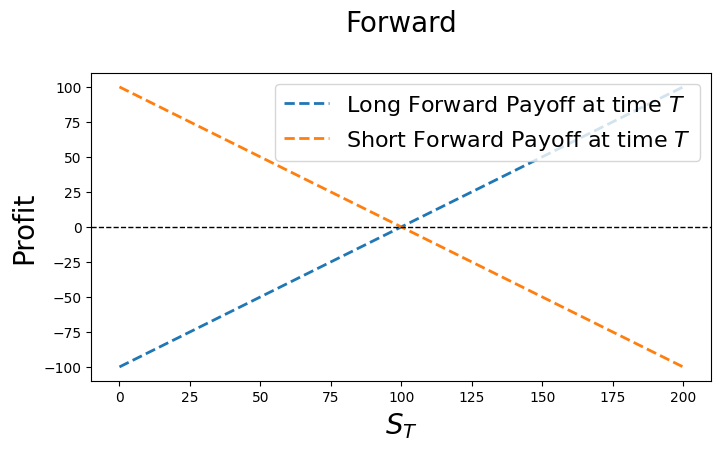

In [4]:
layout = {
    'title': 'Forward',
    'x_label': '$S_{T}$',
    'x_label_font': 20,
    'y_label': 'Profit',
    'y_label_font': 20,
    'linewidth':2,
    'linestyle': '--'
}
my_plotter(x_stock_price, [y_forward_payoff, y_forward_payoff__short], layout=layout, names=['Long Forward Payoff at time $T$', 'Short Forward Payoff at time $T$'])

# HW 2/2

Upgrade the BSM call option pricer to be able to return the greeks as well, not just the price.

In [5]:
from scipy.stats import norm

"""The pricing function of European call option"""
def black_scholes_eur_call(r: float, T: float, S0: float, sigma: float, K: Union[float, List[float], np.ndarray], return_greeks=False) -> np.ndarray:
    """
    Black-Scholes pricer of European call option on non-dividend-paying stock

    param r: risk-free interest rate (which is constant)
    param T: time to maturity (in years)
    param S0: initial spot price of the underlying stock
    param sigma: volatility of the underlying stock
    param K: strike price (or prices)
    """
    # check conditions
    assert sigma > 0

    K = np.array([K]) if isinstance(K, float) else np.array(K)

    d1_vec = ( np.log( S0 / K ) + ( r + 0.5 * sigma**2 ) * T ) / ( sigma * T**0.5 )
    d2_vec = d1_vec - sigma * T**0.5

    N_d1_vec = norm.cdf(d1_vec)
    N_d2_vec = norm.cdf(d2_vec)

    
    if return_greeks:
        return {
            'price': N_d1_vec * S0 - K_vec * np.exp((-1.0)*r*T) * N_d2_vec,
            'delta': N_d1_vec,
            'vega': S0*norm.pdf(d1_vec)*np.sqrt(T),
            'theta': -S0*norm.pdf(d1_vec)*(sigma/(2*np.sqrt(T)))-r*K*np.exp(-r*T)*N_d2_vec,
            'rho': K*T*np.exp(-r*T)*N_d2_vec,
            'gamma': norm.pdf(d1_vec)*(1/(S0*sigma*np.sqrt(T))),
        }
    else:
        return N_d1_vec * S0 - K_vec * np.exp((-1.0)*r*T) * N_d2_vec

In [6]:
K_vec = np.arange(10, 11, 0.5)

# Time to maturities (in year fractions)
T_vec = [1.0, 2.0, 5.0]

for _T in T_vec:
    print(black_scholes_eur_call(r=0.05, T=_T, S0=20.0, sigma=0.3, K=K_vec, return_greeks=True))

{'price': array([10.49652216, 10.02683252]), 'delta': array([0.99569492, 0.99314022]), 'vega': array([0.25304602, 0.38283774]), 'theta': array([-0.50882572, -0.54922426]), 'rho': array([9.41737631, 9.83597187]), 'gamma': array([0.00210872, 0.00319031])}
{'price': array([11.01872477, 10.59117435]), 'delta': array([0.98131039, 0.97538523]), 'vega': array([1.29284148, 1.63168431]), 'theta': array([-0.52733726, -0.56820284]), 'rho': array([17.21496613, 17.83306062]), 'gamma': array([0.00538684, 0.00679868])}
{'price': array([12.50315039, 12.17241212]), 'delta': array([0.95919072, 0.95240552]), 'vega': array([3.91700062, 4.43414483]), 'theta': array([-0.45154322, -0.47680926]), 'rho': array([33.40331967, 34.37849135]), 'gamma': array([0.00652833, 0.00739024])}


# HW 2/3

Implement the BSM pricer for European put option.

The formula:
\begin{equation}
c = K\cdot e^{-rT} \cdot N(-d_2) - S_0 \cdot N(-d_1)
\end{equation}

In [7]:
def black_scholes_eur_put(r: float, T: float, S0: float, sigma: float, K: Union[float, List[float], np.ndarray], return_greeks=False) -> np.ndarray:
    """
    Black-Scholes pricer of European call option on non-dividend-paying stock

    param r: risk-free interest rate (which is constant)
    param T: time to maturity (in years)
    param S0: initial spot price of the underlying stock
    param sigma: volatility of the underlying stock
    param K: strike price (or prices)
    """
    # check conditions
    assert sigma > 0

    K = np.array([K]) if isinstance(K, float) else np.array(K)

    d1_vec = ( np.log( S0 / K ) + ( r + 0.5 * sigma**2 ) * T ) / ( sigma * T**0.5 )
    d2_vec = d1_vec - sigma * T**0.5

    # === Only this changes ===
    N_minus_d1_vec = norm.cdf(-d1_vec)
    N_minus_d2_vec = norm.cdf(-d2_vec)

    return K_vec * np.exp((-1.0)*r*T) * N_minus_d2_vec - N_minus_d1_vec * S0

In [8]:
K_vec = np.arange(10, 11, 0.5)

# Time to maturities (in year fractions)
T_vec = [1.0, 2.0, 5.0]

for _T in T_vec:
    print("Price:", black_scholes_eur_put(r=0.05, T=_T, S0=20.0, sigma=0.3, K=K_vec))

Price: [0.00881641 0.01474148]
Price: [0.06709895 0.09196724]
Price: [0.29115822 0.34982035]


# HM 2/4

With the call and put pricer, check if Put-Call parity holds in practice.

In [9]:
K_vec = np.arange(10, 11, 0.5)

# Time to maturities (in year fractions)
T_vec = [0.5, 1.0, 2.0, 5.0]

for _T in T_vec:

    call = black_scholes_eur_call(r=0.05, T=_T, S0=20.0, sigma=0.3, K=K_vec)
    put = black_scholes_eur_put(r=0.05, T=_T, S0=20.0, sigma=0.3, K=K_vec)
    diff = call-put
    dividends = 20.0-K_vec*np.exp(-0.05*_T)
    print("Call", call)
    print("Put", put)
    print("Difference:", diff)
    print("S0-K*exp(-rT):", dividends)
    print("No Hedge", np.isclose(np.abs(diff-dividends), 0))
    print()

Call [10.24717127  9.7599057 ]
Put [0.00027039 0.00065978]
Difference: [10.24690088  9.75924592]
S0-K*exp(-rT): [10.24690088  9.75924592]
No Hedge [ True  True]

Call [10.49652216 10.02683252]
Put [0.00881641 0.01474148]
Difference: [10.48770575 10.01209104]
S0-K*exp(-rT): [10.48770575 10.01209104]
No Hedge [ True  True]

Call [11.01872477 10.59117435]
Put [0.06709895 0.09196724]
Difference: [10.95162582 10.49920711]
S0-K*exp(-rT): [10.95162582 10.49920711]
No Hedge [ True  True]

Call [12.50315039 12.17241212]
Put [0.29115822 0.34982035]
Difference: [12.21199217 11.82259178]
S0-K*exp(-rT): [12.21199217 11.82259178]
No Hedge [ True  True]

